# ĐỀ TÀI: MÔ HÌNH AI DỰ ĐOÁN GIÁ NHÀ Ở PHƯỜNG PHÚ HÒA, TP. THỦ DẦU MỘT

**Mã sinh viên:** 2324801030095
**Họ và tên:** Nguyễn Quang Long
**Lớp:** D23KTPM01
**Môn:** Học máy

**Bài toán:** cho thông tin một căn nhà (diện tích đất, mặt tiền, số tầng, số phòng, vị trí hẻm/mặt đường, ...), mô hình dự đoán **giá bán (tỷ đồng)**. Đây là bài toán **học có giám sát – hồi quy**: biến mục tiêu là giá, là một số liên tục.

**Quy trình** (theo các bước trong bài giảng):
1. Thu thập dữ liệu → 2. Khám phá dữ liệu → 3. Tiền xử lý → 4. Xây dựng mô hình → 5. Đánh giá → 6. Lưu mô hình và dự đoán.

> Chạy lần lượt các ô từ trên xuống (Restart & Run All). Notebook đọc dữ liệu trong thư mục `data/` và ghi mô hình ra thư mục `model/`.

## Bước 1: Thu thập dữ liệu

- **Nguồn:** tin rao bán trên [guland.vn](https://guland.vn/mua-ban-bat-dong-san-phuong-phu-hoa-thanh-pho-thu-dau-mot-binh-duong), mục *Mua bán – Phường Phú Hòa, TP. Thủ Dầu Một, Bình Dương*.
- **Ngày thu thập:** 12/11/2026. Trang có 391 tin; lấy được 378 tin khác nhau (đất, nhà, căn hộ).
- **Cách lấy:** script `thu_thap/guland_thu_thap.js` duyệt các trang danh sách, sau đó vào trang chi tiết từng tin để đọc bảng thông số (diện tích, mặt tiền, số tầng, phòng ngủ, vị trí, pháp lý, ...).
- **Phạm vi đề tài:** chỉ giữ **190 tin loại "Nhà phố"** (nhà ở có công trình). Tin đất trống và căn hộ chung cư có cơ chế định giá khác nên không đưa vào.
- **Lưu ý địa giới:** sau sắp xếp đơn vị hành chính năm 2025, Phú Hòa cũ thuộc phường Phú Lợi, TP. Hồ Chí Minh; trên guland các tin vẫn được gắn nhãn "Phường Phú Hòa, Thủ Dầu Một".
- **Giới hạn:** giá là **giá rao bán** của người đăng, chưa phải giá giao dịch thực tế. Một số thông số do người đăng tự nhập nên có thể sai hoặc thiếu.

Nạp thư viện và đặt cấu hình chung.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 40)

RANDOM_STATE = 42          # cố định để kết quả chạy lại giống nhau
DATA_DIR = Path("data")
MODEL_DIR = Path("model")
MODEL_DIR.mkdir(exist_ok=True)

Đọc tệp dữ liệu gốc. Mỗi dòng là một tin rao bán nhà, mỗi cột là một thông số của căn nhà.

In [2]:
df_raw = pd.read_csv(DATA_DIR / "nha_phu_hoa_guland_raw.csv")
print("Kích thước dữ liệu gốc:", df_raw.shape)
df_raw.head()

Kích thước dữ liệu gốc: (190, 33)


,id,url,ngay_thu_thap,tieu_de,gia,loai_bds,dac_diem,duong,cap_nhat,dt_dat,dt_thocu,mat_tien,chieu_dai,huong,hinh_dang,mat_thoang,dt_xaydung,so_tang,dt_san,phong_ngu,phong_tam,tang_ham,nam_xay,loai_ct,vi_tri,hem_rong,hien_trang_duong,loai_so,tinh_trang_so,noi_that,pn_mota,wc_mota,tret_lau_mota
0,1385088,https://guland.vn/post/x-1385088,2026-11-12,Nhà cấp 4 Phú Hoà (phường Phú Lợi-TP.HCM) đườn...,2.300000e+09,Nhà phố,Nhà phố,Đường Nguyễn Thái Bình,13 giờ trước,98.4,98.4,5.0,NaN,Nam,Vuông vắn / chữ nhật chuẩn,1 mặt tiền (tiêu chuẩn),80.0,1.0,80.0,2.0,NaN,Không,5 năm,Nhà mái bằng kết cấu Bê tông cốt thép,"Hẻm 1 xe hơi (3,5m ≤ rộng < 5m)",3.0,Đường bê tông,Sổ hồng,Sổ sẵn,NaN,2.0,NaN,cap4
1,2129755,https://guland.vn/post/x-2129755,2026-11-12,Cân bán căn happy one vạn xuân gia 1 ty 550,1.550000e+09,Nhà phố,Nhà phố,NaN,15 giờ trước,54.0,50.0,5.0,NaN,NaN,Vuông vắn / chữ nhật chuẩn,1 mặt tiền (tiêu chuẩn),50.0,3.0,150.0,NaN,NaN,Không,8 năm,Nhà phố liên kế từ 2 - 3 tầng (Khung kết cấu B...,Mặt đường chính,NaN,NaN,Sổ hồng,Sổ sẵn,NaN,2.0,2.0,NaN
2,2580239,https://guland.vn/post/x-2580239,2026-11-12,giảm giá sâu còn 2 tỷ 290 triệu Nhà Sổ riêng g...,2.290000e+09,Nhà phố,Nhà phố,NaN,16 giờ trước,103.0,0.0,0.0,NaN,NaN,Vuông vắn / chữ nhật chuẩn,1 mặt tiền (tiêu chuẩn),103.0,NaN,NaN,NaN,NaN,Không,2 năm,Nhà mái bằng kết cấu Bê tông cốt thép,"Hẻm 1 xe hơi (3,5m ≤ rộng < 5m)",3.0,NaN,Sổ hồng,Sổ sẵn,NaN,3.0,2.0,gac
3,2580201,https://guland.vn/post/x-2580201,2026-11-12,BÁN NHÀ TDM - PHÚ HOÀ 100% mới 4x30 - sân rộng...,3.850000e+09,Nhà phố,Nhà phố,NaN,16 giờ trước,120.0,0.0,0.0,NaN,NaN,Vuông vắn / chữ nhật chuẩn,1 mặt tiền (tiêu chuẩn),120.0,NaN,NaN,NaN,NaN,Không,2 năm,Nhà mái bằng kết cấu Bê tông cốt thép,"Hẻm xe tải, 2 ô tô tránh (5m ≤ rộng < 7m)",5.0,NaN,Sổ hồng,Sổ sẵn,NaN,3.0,2.0,1+1
4,2580097,https://guland.vn/post/x-2580097,2026-11-12,Bán Nhà riêng 68m2 giá 2.85 tỷ tại - Chọn - Ph...,2.850000e+09,Nhà phố,Nhà phố,NaN,16 giờ trước,68.0,68.0,0.0,NaN,NaN,Vuông vắn / chữ nhật chuẩn,1 mặt tiền (tiêu chuẩn),68.0,1.0,68.0,NaN,NaN,Không,2 năm,Nhà đơn giản / Nhà ở xã hội (Nhà 1 tầng kết cấ...,Mặt đường chính,5.0,NaN,Sổ hồng,Sổ sẵn,NaN,2.0,2.0,NaN


**Ý nghĩa các cột chính**

| Cột | Ý nghĩa |
|---|---|
| `gia` | Giá rao bán (đồng) → **biến mục tiêu** |
| `dt_dat`, `dt_thocu` | Tổng diện tích đất, diện tích đất thổ cư (m²) |
| `mat_tien`, `chieu_dai` | Chiều ngang mặt tiền, chiều dài lô đất (m) |
| `so_tang`, `dt_san`, `dt_xaydung` | Số tầng, tổng diện tích sàn, diện tích xây dựng (m²) |
| `phong_ngu`, `phong_tam` | Số phòng ngủ, phòng tắm (ô thông số) |
| `pn_mota`, `wc_mota`, `tret_lau_mota` | Số phòng ngủ / WC / kiểu "1 trệt 2 lầu" đọc từ phần mô tả tin |
| `vi_tri`, `hem_rong` | Mặt đường hay hẻm (và loại hẻm), độ rộng đường/hẻm (m) |
| `duong` | Tên đường |
| `loai_so`, `tinh_trang_so` | Loại giấy tờ (sổ hồng), sổ sẵn hay đang cầm ngân hàng |
| `nam_xay`, `noi_that` | Số năm đã xây, tình trạng nội thất |

In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 190 entries, 0 to 189
Data columns (total 33 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                190 non-null    int64  
 1   url               190 non-null    str    
 2   ngay_thu_thap     190 non-null    str    
 3   tieu_de           190 non-null    str    
 4   gia               190 non-null    float64
 5   loai_bds          190 non-null    str    
 6   dac_diem          190 non-null    str    
 7   duong             102 non-null    str    
 8   cap_nhat          190 non-null    str    
 9   dt_dat            190 non-null    float64
 10  dt_thocu          186 non-null    float64
 11  mat_tien          186 non-null    float64
 12  chieu_dai         141 non-null    float64
 13  huong             75 non-null     str    
 14  hinh_dang         190 non-null    str    
 15  mat_thoang        190 non-null    str    
 16  dt_xaydung        176 non-null    float64
 17  so_tang 

Đếm tỷ lệ ô trống của từng cột để biết cột nào dùng được.

In [4]:
ty_le_thieu = (df_raw.isna().mean() * 100).round(1).sort_values(ascending=False)
ty_le_thieu[ty_le_thieu > 0].to_frame("% thiếu")

,% thiếu
noi_that,93.2
phong_tam,83.7
wc_mota,63.7
huong,60.5
phong_ngu,56.3
tret_lau_mota,50.5
hien_trang_duong,47.9
hem_rong,46.8
duong,46.3
pn_mota,43.7


**Quan sát:** Bảng có 190 tin nhà. Giá (`gia`) và diện tích đất (`dt_dat`) đầy đủ 100%; mặt tiền và diện tích thổ cư chỉ thiếu 2%. Nhiều ô thông số do người đăng tự chọn có nhiều chỗ trống: nội thất thiếu 93%, phòng tắm 84%, hướng 61%, phòng ngủ 56%, độ rộng hẻm 47%. Vì vậy:
- bỏ cột `huong` (hướng nhà) vì thiếu quá nửa và ít liên quan tới giá;
- số phòng ngủ / WC / số tầng được **bổ sung từ phần mô tả tin** (`pn_mota`, `wc_mota`, `tret_lau_mota`) trước khi xử lý thiếu.

## Bước 2: Khám phá dữ liệu

Đổi giá sang **tỷ đồng** cho dễ đọc và tính **đơn giá (triệu/m² đất)**.

In [5]:
df = df_raw.copy()
df["gia_ty"] = df["gia"] / 1e9
df["don_gia_tr_m2"] = df["gia"] / df["dt_dat"] / 1e6
df[["gia_ty", "dt_dat", "don_gia_tr_m2"]].describe().round(2)

,gia_ty,dt_dat,don_gia_tr_m2
count,190.00,190.00,190.00
mean,10.48,209.36,39.13
std,54.55,432.90,17.08
min,1.55,52.00,11.50
25%,2.85,82.25,28.68
50%,3.85,109.50,35.95
75%,6.45,168.72,43.85
max,750.00,4700.00,159.57


**Quan sát:** Giá trung vị là **3,85 tỷ**, nhưng giá trung bình lên tới 10,48 tỷ: có vài tin cực lớn (tối đa 750 tỷ cho khu đất 4.700 m²) kéo trung bình lên. 75% số tin có giá dưới 6,45 tỷ. Diện tích đất trung vị 109,5 m². Đơn giá trung vị khoảng **36 triệu/m²**, phần lớn tin nằm trong khoảng 29–44 triệu/m².

Biểu đồ phân bố giá: bên trái là giá gốc, bên phải là log(giá).

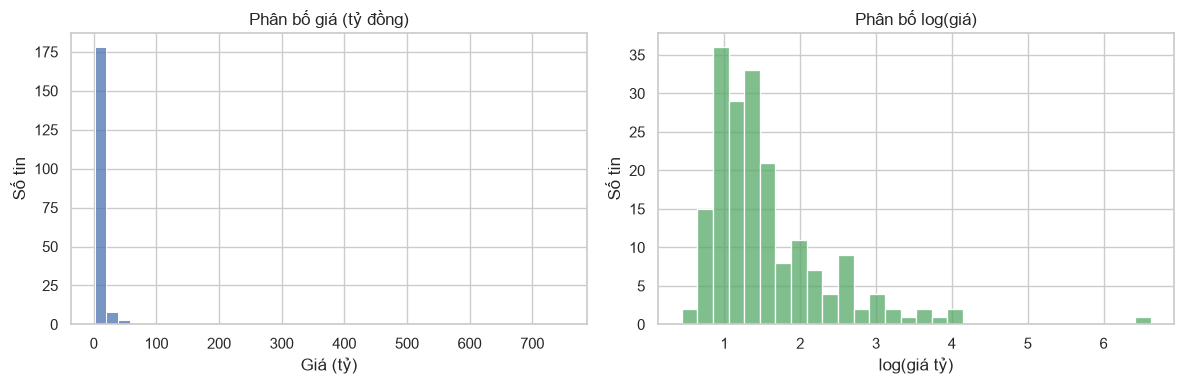

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["gia_ty"], bins=40, ax=axes[0], color="#4C72B0")
axes[0].set(title="Phân bố giá (tỷ đồng)", xlabel="Giá (tỷ)", ylabel="Số tin")
sns.histplot(np.log(df["gia_ty"]), bins=30, ax=axes[1], color="#55A868")
axes[1].set(title="Phân bố log(giá)", xlabel="log(giá tỷ)", ylabel="Số tin")
plt.tight_layout()
plt.show()

**Quan sát:** Giá gốc **lệch phải rất mạnh**: hầu hết dưới 10 tỷ, một số ít rất đắt. Sau khi lấy log, phân bố gọn hơn nhiều, chỉ còn một điểm tách xa hẳn (tin 750 tỷ, log ≈ 6,6). Đây là lý do mô hình sẽ học trên **log(giá)** và cần lọc ngoại lai ở Bước 3.

Quan hệ giữa diện tích đất và giá (cả hai trục dùng thang log để thấy rõ các căn lớn).

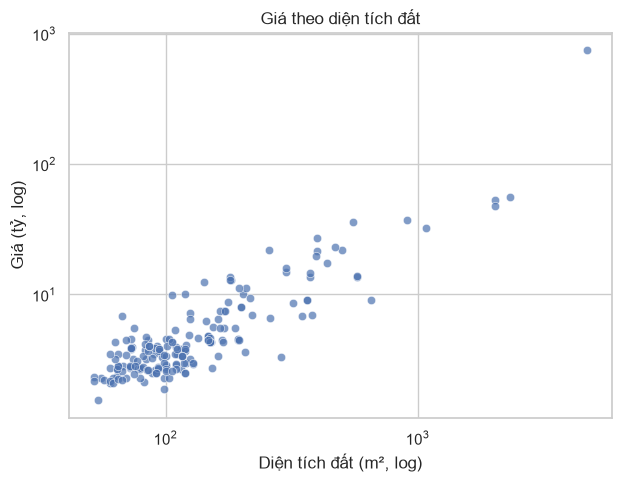

In [7]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=df, x="dt_dat", y="gia_ty", ax=ax, alpha=0.7)
ax.set(xscale="log", yscale="log", xlabel="Diện tích đất (m², log)", ylabel="Giá (tỷ, log)",
       title="Giá theo diện tích đất")
plt.show()

**Quan sát:** Trên thang log–log, các điểm xếp gần một đường thẳng đi lên: **diện tích đất là yếu tố quyết định chính** của giá. Tuy vậy, với cùng diện tích, giá vẫn chênh nhiều (ví dụ quanh 100 m², giá dao động từ khoảng 2 tới 7 tỷ). Phần chênh lệch này đến từ vị trí, số tầng, chất lượng nhà, và mô hình cần các đặc trưng khác để giải thích. Các tin trên 500 m² nằm thành nhóm riêng (đất lớn, mặt bằng kinh doanh).

## Bước 3: Tiền xử lý dữ liệu

### 3.1 Bỏ tin trùng
Một căn có thể được đăng nhiều lần (cùng giá, diện tích, mặt tiền, số tầng). Chỉ giữ 1 tin để không đếm trùng khi huấn luyện và đánh giá.

In [8]:
so_dong_truoc = len(df)
df = df.drop_duplicates(subset=["gia", "dt_dat", "mat_tien", "so_tang"]).reset_index(drop=True)
print(f"Bỏ {so_dong_truoc - len(df)} tin trùng → còn {len(df)} tin")

Bỏ 10 tin trùng → còn 180 tin


### 3.2 Loại giá trị ngoại lai
Đề tài nhắm tới **nhà ở dân dụng**. Các tin có diện tích đất rất lớn (khu đất vài nghìn m², giá vài chục đến hàng trăm tỷ) thực chất là bán quỹ đất hoặc mặt bằng kinh doanh, nên được loại.
Ngưỡng giữ lại: **diện tích đất 40–500 m²** và **giá 1–30 tỷ**.

In [9]:
ngoai_lai = df[~(df["dt_dat"].between(40, 500) & df["gia_ty"].between(1, 30))]
print("Số tin bị loại:", len(ngoai_lai))
display(ngoai_lai[["id", "tieu_de", "gia_ty", "dt_dat"]].sort_values("gia_ty", ascending=False))

df = df[df["dt_dat"].between(40, 500) & df["gia_ty"].between(1, 30)].reset_index(drop=True)
print("Còn lại:", len(df), "tin")

Số tin bị loại: 10


,id,tieu_de,gia_ty,dt_dat
85,2880214,Bán nhà 4.700m² 3 tầng ngang 42m tại Đại Lộ Bì...,750.0,4700.0
73,2899574,Bán nhà 2.322m² 2 tầng ngang 27m tại đường Ngu...,56.0,2322.0
71,2902696,"Bán nhà 2.023m² 2 tầng ngang 16,8m nở hậu 27,3...",53.5,2023.0
98,2865847,"Bán nhà 2.023m² 2 tầng ngang 19m nở hậu 27,3m ...",48.0,2023.0
106,1284731,Đất biệt thự mặt tiền Trần Văn Giác phường Phú...,37.0,911.0
87,2874055,"Bán nhà 553m² 2 tầng ngang 12,4m nở hậu 13,3m ...",36.0,553.0
167,1534285,Bán Nhà hơn 1000m2 mặt tiền Nguyễn Thị Minh Kh...,32.4,1080.0
84,2881293,"Bán nhà 577m² cấp 4 ngang 14,7m tại Phú Hòa, T...",13.8,577.0
69,2903843,"Bán nhà 577m² cấp 4 ngang 14,7m tại Phú Hòa, T...",13.5,577.0
38,2682302,"Đất mặt tiền Nguyễn Thị Minh Khai – 652,8 m² -...",9.0,652.8


Còn lại: 170 tin


### 3.3 Tạo đặc trưng (feature engineering)
Chuyển các cột thô thành đặc trưng dạng số cho mô hình:

- **so_tang_x:** ưu tiên kiểu nhà ghi trong mô tả ("cấp 4" = 1 tầng, "gác lửng" = 1,5, "1 trệt 2 lầu" = 3); nếu không có thì dùng ô "Số tầng".
- **phong_ngu_x, so_wc:** lấy từ ô thông số, nếu trống thì lấy số đọc được trong mô tả; giá trị > 10 là lỗi nhập nên đặt là thiếu.
- **mat_tien_x, hem_rong_x, dt_san_x:** giá trị 0 là "không nhập", đổi thành thiếu.
- **vi_tri_cap:** mã hóa thứ bậc độ rộng lối vào: hẻm nhỏ (0) → hẻm xe máy (1) → hẻm 1 xe hơi (2) → hẻm xe tải (3) → hẻm rất lớn (4) → mặt đường chính (5).
- **duong_ntmk, duong_lhp:** nằm trên trục đường Nguyễn Thị Minh Khai / Lê Hồng Phong (hai trục có nhiều tin nhất) – mã hóa one-hot.
- **Không dùng cột loại sổ:** 94% tin ghi "Sổ hồng"; 11 tin bỏ trống ô này phần lớn là nhà mặt tiền/biệt thự giá cao, nên cột này phản ánh cách người đăng điền form chứ không phản ánh pháp lý thật. Đưa vào sẽ làm mô hình học sai rằng "không có sổ thì giá cao hơn".
- **Không dùng số năm đã xây:** 140/190 tin ghi đúng "8 năm", là giá trị mặc định của form đăng tin chứ không phải tuổi nhà thật. Đưa vào sẽ làm mô hình học sai rằng nhà mới rẻ hơn.
- **noi_that_x:** tin có nhắc tới nội thất (1/0).

In [10]:
def tinh_so_tang(row):
    kieu = row["tret_lau_mota"]
    if isinstance(kieu, str):
        if kieu == "cap4":
            return 1.0
        if kieu == "gac":
            return 1.5
        if kieu.startswith("1+"):
            return 1 + int(kieu[2:])
    return row["so_tang"]

MA_VI_TRI = {
    "Hẻm nhỏ, sâu, cụt (< 2,5m)": 0,
    "Hẻm xe máy (2,5m ≤ rộng < 3,5m)": 1,
    "Hẻm 1 xe hơi (3,5m ≤ rộng < 5m)": 2,
    "Hẻm xe tải, 2 ô tô tránh (5m ≤ rộng < 7m)": 3,
    "Hẻm rất lớn, 2 xe tải tránh nhau (7m ≤ rộng < 10m)": 4,
    "Mặt đường chính": 5,
}

df["so_tang_x"] = df.apply(tinh_so_tang, axis=1)
df["phong_ngu_x"] = df["phong_ngu"].fillna(df["pn_mota"]).where(lambda s: s <= 10)
df["so_wc"] = df["phong_tam"].fillna(df["wc_mota"]).where(lambda s: s <= 10)
df["mat_tien_x"] = df["mat_tien"].replace(0, np.nan)
df["hem_rong_x"] = df["hem_rong"].replace(0, np.nan)
df["dt_san_x"] = df["dt_san"].replace(0, np.nan)
df["vi_tri_cap"] = df["vi_tri"].map(MA_VI_TRI)
duong = df["duong"].fillna("")
df["duong_ntmk"] = duong.str.contains("Minh Khai", case=False).astype(int)
df["duong_lhp"] = duong.str.contains("Lê Hồng Phong", case=False).astype(int)
df["nam"] = df["nam_xay"].str.extract(r"(\d+)", expand=False).astype(float)
df["noi_that_x"] = (df["noi_that"].isin(["Đầy đủ nội thất", "Nội thất cơ bản"])
                    | df["tieu_de"].str.contains("nội thất", case=False)).astype(int)

FEATURES = ["dt_dat", "mat_tien_x", "so_tang_x", "dt_san_x", "phong_ngu_x", "so_wc", "vi_tri_cap",
            "hem_rong_x", "duong_ntmk", "duong_lhp", "noi_that_x"]
TEN_DAC_TRUNG = {
    "dt_dat": "Diện tích đất (m²)", "mat_tien_x": "Mặt tiền (m)", "so_tang_x": "Số tầng",
    "dt_san_x": "Diện tích sàn (m²)", "phong_ngu_x": "Phòng ngủ", "so_wc": "Số WC",
    "vi_tri_cap": "Cấp vị trí (hẻm→mặt đường)", "hem_rong_x": "Đường/hẻm rộng (m)",
    "duong_ntmk": "Trục Nguyễn Thị Minh Khai", "duong_lhp": "Trục Lê Hồng Phong",
    "noi_that_x": "Có nội thất",
}
df[FEATURES + ["gia_ty"]].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
dt_dat,170.0,134.46,88.37,52.00,80.35,103.25,152.30,500.0
mat_tien_x,115.0,6.45,3.20,3.60,4.15,5.00,7.35,19.0
so_tang_x,155.0,1.79,0.81,1.00,1.00,2.00,2.00,4.0
dt_san_x,142.0,197.48,216.38,42.30,84.25,138.00,239.25,2000.0
phong_ngu_x,117.0,2.67,0.84,1.00,2.00,3.00,3.00,5.0
so_wc,75.0,2.37,1.16,1.00,2.00,2.00,3.00,7.0
vi_tri_cap,151.0,2.68,1.53,0.00,2.00,2.00,3.00,5.0
hem_rong_x,71.0,5.49,3.89,2.50,4.00,4.50,5.50,30.0
duong_ntmk,170.0,0.19,0.40,0.00,0.00,0.00,0.00,1.0
duong_lhp,170.0,0.16,0.37,0.00,0.00,0.00,0.00,1.0


Tỷ lệ thiếu của các đặc trưng sau khi tạo.

In [11]:
(df[FEATURES].isna().mean() * 100).round(1).to_frame("% thiếu").T

,dt_dat,mat_tien_x,so_tang_x,dt_san_x,phong_ngu_x,so_wc,vi_tri_cap,hem_rong_x,duong_ntmk,duong_lhp,noi_that_x
% thiếu,0.0,32.4,8.8,16.5,31.2,55.9,11.2,58.2,0.0,0.0,0.0


**Quan sát:** Sau khi bổ sung từ mô tả, các đặc trưng vẫn thiếu đáng kể: độ rộng hẻm 58%, số WC 56%, mặt tiền 32%, phòng ngủ 31%. Các ô thiếu được điền bằng **trung vị tập train** trong `Pipeline`. Cách điền này đơn giản và không rò rỉ dữ liệu test, nhưng làm các đặc trưng thiếu nhiều mất bớt thông tin. Đây là một giới hạn của dữ liệu tin rao.

### 3.4 Tương quan giữa đặc trưng và giá
Dùng hệ số tương quan Spearman (dựa trên thứ hạng, ít bị ảnh hưởng bởi giá trị cực lớn) giữa từng đặc trưng và giá.

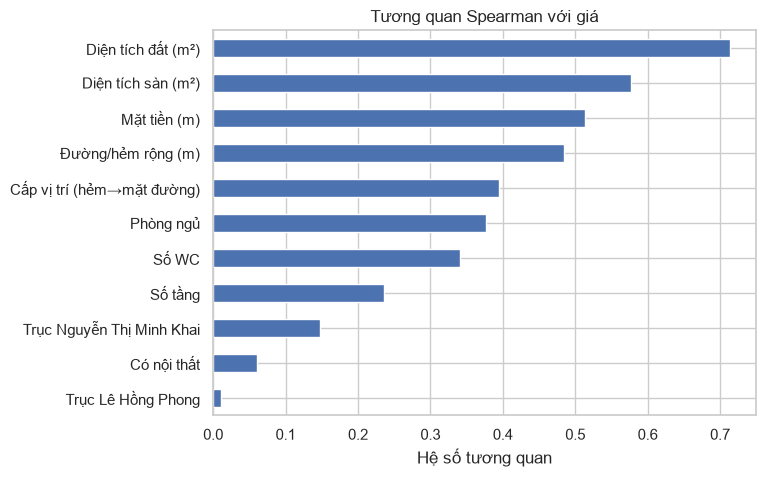

In [12]:
tuong_quan = df[FEATURES + ["gia_ty"]].corr(method="spearman")["gia_ty"].drop("gia_ty").sort_values()
fig, ax = plt.subplots(figsize=(7, 5))
tuong_quan.rename(TEN_DAC_TRUNG).plot.barh(ax=ax, color=np.where(tuong_quan > 0, "#4C72B0", "#C44E52"))
ax.set(title="Tương quan Spearman với giá", xlabel="Hệ số tương quan")
plt.show()

**Quan sát:** Diện tích đất có tương quan mạnh nhất với giá (≈ 0,71), tiếp theo là diện tích sàn (≈ 0,58), mặt tiền (≈ 0,51), độ rộng hẻm (≈ 0,49) và cấp vị trí (≈ 0,39). Số phòng ngủ, WC, số tầng tương quan vừa phải. Trục đường và nội thất gần như không liên quan. Lưu ý: các đặc trưng "kích thước" liên quan với nhau (nhà to thì nhiều phòng hơn), nên tương quan từng cột không cộng dồn được.

Đơn giá trung bình theo vị trí: nhà mặt đường so với nhà trong hẻm.

In [13]:
nhan_vi_tri = {v: k.split(" (")[0] for k, v in MA_VI_TRI.items()}
bang_vt = (df.assign(vi_tri_ten=df["vi_tri_cap"].map(nhan_vi_tri).fillna("Không rõ"))
             .groupby("vi_tri_ten")
             .agg(so_tin=("gia_ty", "size"), gia_trung_vi_ty=("gia_ty", "median"),
                  don_gia_trung_vi_tr_m2=("don_gia_tr_m2", "median"))
             .sort_values("don_gia_trung_vi_tr_m2"))
bang_vt.round(2)

,so_tin,gia_trung_vi_ty,don_gia_trung_vi_tr_m2
vi_tri_ten,,,
Hẻm xe máy,2,2.76,25.22
"Hẻm nhỏ, sâu, cụt",19,2.70,29.38
Hẻm 1 xe hơi,56,3.42,34.56
"Hẻm xe tải, 2 ô tô tránh",39,3.95,38.89
Mặt đường chính,33,4.45,39.68
"Hẻm rất lớn, 2 xe tải tránh nhau",2,12.30,42.92
Không rõ,19,4.55,43.96


**Quan sát:** Đơn giá trung vị **tăng dần theo độ rộng lối vào**: hẻm nhỏ/cụt ≈ 29,4 triệu/m² → hẻm 1 xe hơi ≈ 34,6 → hẻm xe tải ≈ 38,9 → mặt đường chính ≈ 39,7 triệu/m². Điều này khớp với thực tế thị trường và cho thấy mã hóa thứ bậc `vi_tri_cap` là hợp lý. Hai nhóm "hẻm xe máy" và "hẻm rất lớn" mỗi nhóm chỉ có 2 tin nên không đủ để kết luận.

### 3.5 Chuẩn bị dữ liệu huấn luyện
- **X** = 11 đặc trưng, **y** = **log(giá)**. Lấy log vì giá lệch phải; mô hình học trên log rồi đổi ngược `exp()` khi báo kết quả. Cách này làm sai số tính theo **tỷ lệ phần trăm**, hợp lý vì sai 300 triệu với căn 2 tỷ nghiêm trọng hơn với căn 15 tỷ.
- Chia **80% train / 20% test** (`random_state=42`), **phân tầng theo 5 mức giá** để tập test có đủ nhà rẻ, trung bình và đắt. Với chỉ 170 căn, nếu chia ngẫu nhiên thuần túy thì tập test có thể chỉ toàn nhà giá thấp và kết quả bị lệch. Tập test được giữ riêng, chỉ dùng một lần ở Bước 5.
- Giá trị thiếu được điền bằng **trung vị tính trên tập train** (`SimpleImputer` nằm trong `Pipeline`), nên không bị rò rỉ thông tin từ tập test.

In [14]:
from sklearn.model_selection import train_test_split

X = df[FEATURES]
y = np.log(df["gia_ty"])

# Phân tầng theo 5 mức giá để tập test có đủ nhà rẻ, trung bình và đắt như tập train
muc_gia = pd.qcut(y, q=5, labels=False)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE,
                                                    stratify=muc_gia)
print("Train:", X_train.shape, " Test:", X_test.shape)
print(f"Giá trung vị — train: {np.exp(y_train).median():.2f} tỷ, test: {np.exp(y_test).median():.2f} tỷ")

Train: (136, 11)  Test: (34, 11)
Giá trung vị — train: 3.70 tỷ, test: 3.85 tỷ


## Bước 4: Xây dựng mô hình

So sánh 6 mô hình hồi quy:

| Mô hình | Ý tưởng |
|---|---|
| **Baseline – đơn giá trung vị** | Giá = đơn giá/m² trung vị của tập train × diện tích. Mốc tối thiểu mà mô hình AI phải vượt. |
| **Linear Regression** | Giá (log) là tổng có trọng số của các đặc trưng. |
| **Ridge** | Hồi quy tuyến tính có phạt L2, giảm quá khớp khi ít dữ liệu. |
| **KNN** | Giá căn mới ≈ trung bình các căn giống nó nhất. |
| **Random Forest** | Trung bình của nhiều cây quyết định học trên các mẫu ngẫu nhiên. |
| **Gradient Boosting** | Các cây nhỏ học nối tiếp, cây sau sửa sai số của cây trước. |

Đánh giá bằng **kiểm định chéo 5-fold trên tập train** để chọn mô hình. Dữ liệu ít (khoảng 135 căn train), nên điểm trên một lần chia đơn lẻ dao động nhiều; trung bình 5 lần chia ổn định hơn.

**Chỉ số đánh giá** (tính trên giá thật, đơn vị tỷ đồng):
- **MAE:** sai số tuyệt đối trung bình (tỷ).
- **MAPE:** sai số trung bình theo % giá.
- **R²:** tỷ lệ biến thiên của giá mà mô hình giải thích được (1 là hoàn hảo).

In [15]:
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, r2_score


class DonGiaTrungVi(BaseEstimator, RegressorMixin):
    """Baseline: log(giá) = log(đơn giá trung vị) + log(diện tích đất)."""
    def fit(self, X, y):
        self.log_don_gia_ = np.median(y - np.log(X["dt_dat"]))
        return self
    def predict(self, X):
        return self.log_don_gia_ + np.log(X["dt_dat"])


models = {
    "Baseline (đơn giá trung vị)": DonGiaTrungVi(),
    "Linear Regression": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LinearRegression()),
    "Ridge": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=3.0)),
    "KNN (k=7)": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                               KNeighborsRegressor(n_neighbors=7, weights="distance")),
    "Random Forest": make_pipeline(SimpleImputer(strategy="median"),
                                   RandomForestRegressor(n_estimators=400, min_samples_leaf=2,
                                                         random_state=RANDOM_STATE)),
    "Gradient Boosting": make_pipeline(SimpleImputer(strategy="median"),
                                       GradientBoostingRegressor(n_estimators=300, learning_rate=0.03, max_depth=3,
                                                                 subsample=0.8, random_state=RANDOM_STATE)),
}


def danh_gia(y_log_that, y_log_du_doan):
    """Đổi log(giá) về tỷ đồng rồi tính MAE, MAPE, R²."""
    that, du_doan = np.exp(y_log_that), np.exp(y_log_du_doan)
    return {"MAE (tỷ)": mean_absolute_error(that, du_doan),
            "MAPE (%)": mean_absolute_percentage_error(that, du_doan) * 100,
            "R²": r2_score(that, du_doan)}


kfold = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
ket_qua_cv = {}
for ten, mo_hinh in models.items():
    du_doan_cv = cross_val_predict(mo_hinh, X_train, y_train, cv=kfold)
    ket_qua_cv[ten] = danh_gia(y_train, du_doan_cv)

bang_cv = pd.DataFrame(ket_qua_cv).T.sort_values("MAPE (%)")
bang_cv.round(3)

,MAE (tỷ),MAPE (%),R²
Ridge,1.397,23.968,0.721
Linear Regression,1.456,24.497,0.697
Random Forest,1.484,26.424,0.690
Gradient Boosting,1.595,28.113,0.622
Baseline (đơn giá trung vị),1.619,28.745,0.661
KNN (k=7),1.964,29.719,0.304


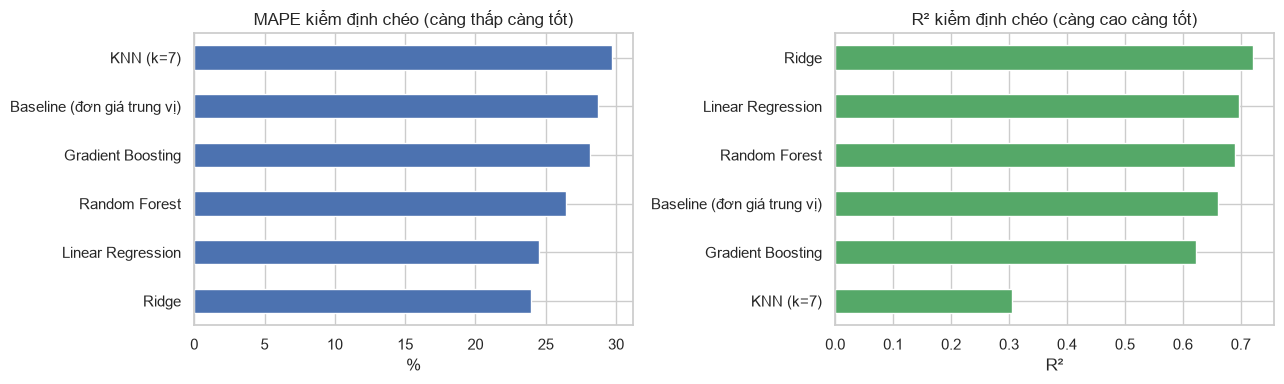

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
bang_cv["MAPE (%)"].sort_values().plot.barh(ax=axes[0], color="#4C72B0")
axes[0].set(title="MAPE kiểm định chéo (càng thấp càng tốt)", xlabel="%")
bang_cv["R²"].sort_values().plot.barh(ax=axes[1], color="#55A868")
axes[1].set(title="R² kiểm định chéo (càng cao càng tốt)", xlabel="R²")
plt.tight_layout()
plt.show()

**Quan sát (kiểm định chéo 5-fold trên 136 căn train):**
- **Ridge tốt nhất ở cả 3 chỉ số:** MAE ≈ 1,40 tỷ, MAPE ≈ 24,0%, R² ≈ 0,72. Baseline đơn giá trung vị chỉ đạt MAE ≈ 1,62 tỷ, MAPE ≈ 28,7%, R² ≈ 0,66.
- Linear Regression đứng ngay sau Ridge. Random Forest và Gradient Boosting không hơn mô hình tuyến tính: với khoảng 136 mẫu, các mô hình cây dễ học thuộc nhiễu, trong khi quan hệ giữa log(giá) và các đặc trưng gần như tuyến tính.
- KNN kém nhất, kém cả baseline: nhiều đặc trưng bị điền trung vị nên "khoảng cách" giữa các căn không còn phản ánh đúng mức giống nhau.

Chọn mô hình có **MAPE kiểm định chéo nhỏ nhất** (không tính baseline). Dùng MAPE làm tiêu chí chính vì mô hình học trên log(giá), tức là tối ưu sai số theo tỷ lệ phần trăm (mục 3.5). Sau đó huấn luyện lại mô hình trên toàn bộ tập train.

In [17]:
ten_tot_nhat = bang_cv.drop("Baseline (đơn giá trung vị)")["MAPE (%)"].idxmin()
mo_hinh_tot = models[ten_tot_nhat].fit(X_train, y_train)
print("Mô hình được chọn:", ten_tot_nhat)

Mô hình được chọn: Ridge


## Bước 5: Đánh giá trên tập test

Tập test (20%) chưa được dùng ở bất kỳ bước nào trước đó, nên kết quả dưới đây phản ánh khả năng dự đoán căn nhà **mới**. Mô hình chọn được so với baseline trên cùng tập test.

In [18]:
baseline = DonGiaTrungVi().fit(X_train, y_train)
bang_test = pd.DataFrame({
    ten_tot_nhat: danh_gia(y_test, mo_hinh_tot.predict(X_test)),
    "Baseline (đơn giá trung vị)": danh_gia(y_test, baseline.predict(X_test)),
}).T
bang_test.round(3)

,MAE (tỷ),MAPE (%),R²
Ridge,1.336,21.776,0.621
Baseline (đơn giá trung vị),1.473,24.897,0.571


**Quan sát:** Trên 34 căn chưa từng thấy, Ridge đạt **MAE ≈ 1,34 tỷ, MAPE ≈ 21,8%, R² ≈ 0,62**, tốt hơn baseline (MAE ≈ 1,47 tỷ, MAPE ≈ 24,9%, R² ≈ 0,57). Kết quả test gần với kết quả kiểm định chéo, nên mô hình **không bị quá khớp**. Sai số khoảng 20% là mức hợp lý khi học từ giá rao bán: chính giá rao đã chứa phần "ảo" và phần thương lượng của người bán.

Biểu đồ giá dự đoán so với giá thật trên tập test. Điểm càng gần đường chéo thì dự đoán càng đúng; hai đường nét đứt là vùng sai ±25%.

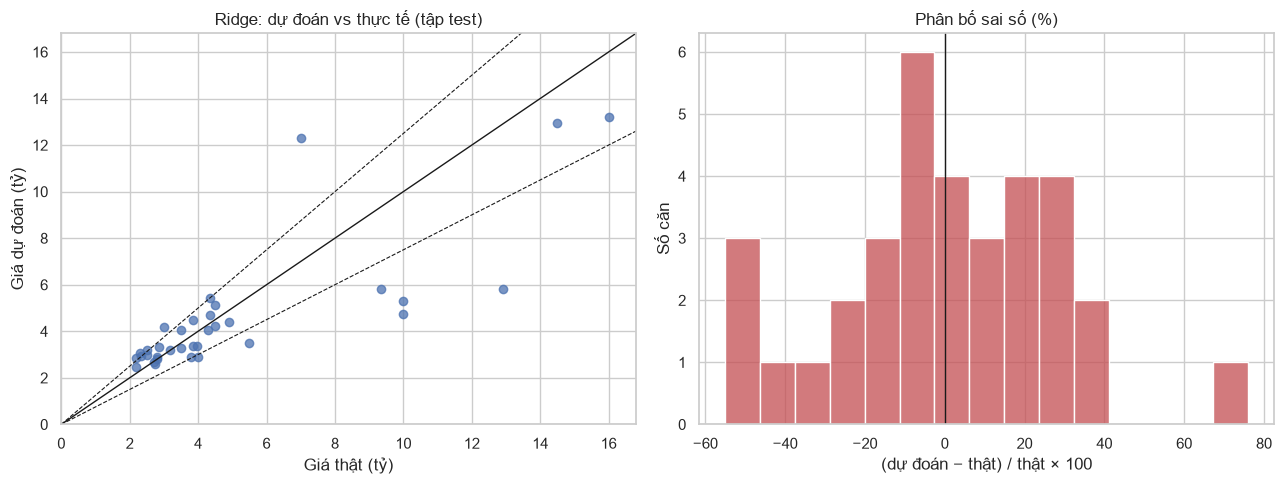

Tỷ lệ căn có sai số trong ±10%: 26%
Tỷ lệ căn có sai số trong ±25%: 62%


In [19]:
gia_that = np.exp(y_test)
gia_du_doan = np.exp(mo_hinh_tot.predict(X_test))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ax = axes[0]
ax.scatter(gia_that, gia_du_doan, alpha=0.75)
lim = [0, max(gia_that.max(), gia_du_doan.max()) * 1.05]
ax.plot(lim, lim, "k-", lw=1)
ax.plot(lim, [v * 1.25 for v in lim], "k--", lw=0.8)
ax.plot(lim, [v * 0.75 for v in lim], "k--", lw=0.8)
ax.set(xlim=lim, ylim=lim, xlabel="Giá thật (tỷ)", ylabel="Giá dự đoán (tỷ)",
       title=f"{ten_tot_nhat}: dự đoán vs thực tế (tập test)")

sai_so_pt = (gia_du_doan - gia_that) / gia_that * 100
sns.histplot(sai_so_pt, bins=15, ax=axes[1], color="#C44E52")
axes[1].axvline(0, color="k", lw=1)
axes[1].set(title="Phân bố sai số (%)", xlabel="(dự đoán − thật) / thật × 100", ylabel="Số căn")
plt.tight_layout()
plt.show()

print(f"Tỷ lệ căn có sai số trong ±10%: {(abs(sai_so_pt) <= 10).mean():.0%}")
print(f"Tỷ lệ căn có sai số trong ±25%: {(abs(sai_so_pt) <= 25).mean():.0%}")

**Quan sát:** Với nhà dưới 6 tỷ (phần lớn thị trường), các điểm bám sát đường chéo. Khoảng 1/4 số căn có sai số trong ±10% và khoảng 3/5 trong ±25%. Sai lớn tập trung ở vài trường hợp:
- nhà trong **khu dân cư quy hoạch** (đường nội bộ D2, N11; 120–203 m², giá khoảng 10–13 tỷ) bị đoán thấp khoảng 50%, vì dữ liệu chưa có đặc trưng "nằm trong khu dân cư";
- một căn cấp 4 rộng 382 m² rao 7 tỷ (≈ 18 triệu/m², thấp hơn mặt bằng chung) bị đoán cao khoảng 76%.

### Đặc trưng nào ảnh hưởng nhiều nhất?
Dùng **permutation importance**: xáo trộn ngẫu nhiên từng cột của tập test rồi đo sai số tăng bao nhiêu. Cột càng quan trọng thì sai số tăng càng nhiều khi bị xáo trộn.

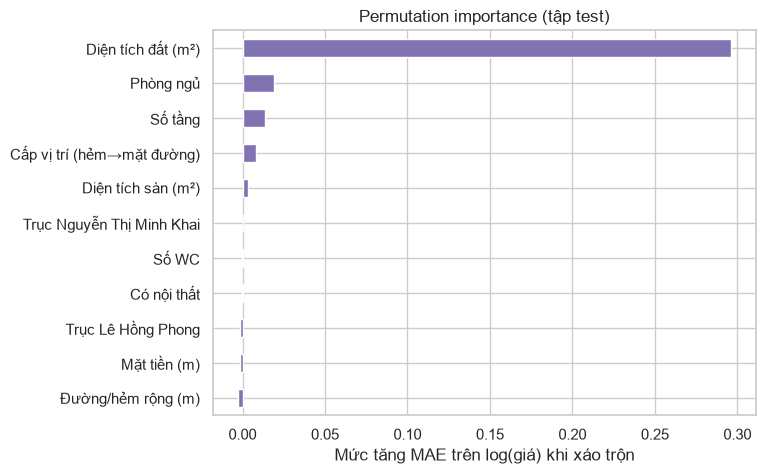

In [20]:
from sklearn.inspection import permutation_importance

pi = permutation_importance(mo_hinh_tot, X_test, y_test, n_repeats=30, random_state=RANDOM_STATE,
                            scoring="neg_mean_absolute_error")
do_quan_trong = pd.Series(pi.importances_mean, index=FEATURES).rename(TEN_DAC_TRUNG).sort_values()
fig, ax = plt.subplots(figsize=(7, 5))
do_quan_trong.plot.barh(ax=ax, color="#8172B2")
ax.set(title="Permutation importance (tập test)", xlabel="Mức tăng MAE trên log(giá) khi xáo trộn")
plt.show()

**Quan sát:** **Diện tích đất** quan trọng vượt trội so với mọi đặc trưng khác. Tiếp theo là số phòng ngủ, số tầng và cấp vị trí (hẻm/mặt đường). Các đặc trưng còn lại có mức đóng góp gần 0 trên tập test: thông tin của chúng đã trùng với diện tích (diện tích sàn, mặt tiền) hoặc bị thiếu nhiều (WC, độ rộng hẻm).

## Bước 6: Lưu mô hình và dự đoán

Huấn luyện lại mô hình đã chọn trên **toàn bộ** 100% dữ liệu (nhiều dữ liệu hơn thì mô hình tốt hơn) rồi lưu:
- `model/mo_hinh_gia_nha.joblib`: mô hình scikit-learn để dùng lại trong Python.
- `model/mo_hinh_gia_nha.json`: tham số mô hình (giá trị điền thiếu + các cây quyết định / hệ số) để trang demo `demo/du_doan_gia_nha.html` tính giá ngay trên trình duyệt.

In [21]:
import json
import joblib

mo_hinh_cuoi = models[ten_tot_nhat].fit(X, y)
joblib.dump(mo_hinh_cuoi, MODEL_DIR / "mo_hinh_gia_nha.joblib")


def xuat_cay(cay):
    t = cay.tree_
    return {"l": t.children_left.tolist(), "r": t.children_right.tolist(), "f": t.feature.tolist(),
            "t": np.round(t.threshold, 6).tolist(), "v": np.round(t.value[:, 0, 0], 6).tolist()}


def xuat_json(pipeline):
    """Ghi các bước của Pipeline thành JSON để trang demo tính lại đúng như Python."""
    buoc = dict(pipeline.named_steps)
    out = {"features": FEATURES, "medians": buoc["simpleimputer"].statistics_.tolist(), "model": ten_tot_nhat}
    if "standardscaler" in buoc:
        out["scaler"] = {"mean": buoc["standardscaler"].mean_.tolist(), "scale": buoc["standardscaler"].scale_.tolist()}
    est = pipeline[-1]
    if isinstance(est, GradientBoostingRegressor):
        out["type"] = "gbr"
        out["init"] = float(est.init_.constant_.ravel()[0])
        out["lr"] = est.learning_rate
        out["trees"] = [xuat_cay(c) for c in est.estimators_[:, 0]]
    elif isinstance(est, RandomForestRegressor):
        out["type"] = "rf"
        out["trees"] = [xuat_cay(c) for c in est.estimators_]
    elif hasattr(est, "coef_"):
        out["type"] = "linear"
        out["coef"] = est.coef_.tolist()
        out["intercept"] = float(est.intercept_)
    else:
        raise ValueError("Trang demo chưa hỗ trợ mô hình này")
    out["cv_mape"] = round(float(bang_cv.loc[ten_tot_nhat, "MAPE (%)"]), 1)
    out["n_samples"] = int(len(X))
    return out


with open(MODEL_DIR / "mo_hinh_gia_nha.json", "w", encoding="utf-8") as f:
    json.dump(xuat_json(mo_hinh_cuoi), f, ensure_ascii=False)

df.to_csv(DATA_DIR / "nha_phu_hoa_da_xu_ly.csv", index=False, encoding="utf-8-sig")
print("Đã lưu:", sorted(p.name for p in MODEL_DIR.iterdir()))

Đã lưu: ['mo_hinh_gia_nha.joblib', 'mo_hinh_gia_nha.json']


Hàm dự đoán cho một căn nhà mới. Thông số nào không biết thì để `None`, mô hình sẽ điền bằng trung vị.

In [22]:
def du_doan_gia(dt_dat, mat_tien=None, so_tang=None, dt_san=None, phong_ngu=None, so_wc=None,
                vi_tri_cap=None, hem_rong=None, duong_ntmk=0, duong_lhp=0, noi_that=0):
    can_nha = pd.DataFrame([[dt_dat, mat_tien, so_tang, dt_san, phong_ngu, so_wc, vi_tri_cap,
                             hem_rong, duong_ntmk, duong_lhp, noi_that]],
                           columns=FEATURES, dtype=float)
    return float(np.exp(mo_hinh_cuoi.predict(can_nha)[0]))


vi_du = {
    "Nhà cấp 4, 100 m², hẻm 1 xe hơi": dict(dt_dat=100, mat_tien=5, so_tang=1, dt_san=100, phong_ngu=2, so_wc=1,
                                              vi_tri_cap=2, hem_rong=4),
    "Nhà 1 trệt 1 lầu, 80 m², hẻm xe tải": dict(dt_dat=80, mat_tien=4.5, so_tang=2, dt_san=160, phong_ngu=3, so_wc=2,
                                                 vi_tri_cap=3, hem_rong=6),
    "Nhà 1 trệt 2 lầu, 120 m², mặt tiền Nguyễn Thị Minh Khai": dict(dt_dat=120, mat_tien=6, so_tang=3, dt_san=300,
                                                                     phong_ngu=4, so_wc=4, vi_tri_cap=5, hem_rong=12,
                                                                     duong_ntmk=1, noi_that=1),
}
pd.DataFrame({"Giá dự đoán (tỷ)": {k: round(du_doan_gia(**v), 2) for k, v in vi_du.items()}})

,Giá dự đoán (tỷ)
"Nhà cấp 4, 100 m², hẻm 1 xe hơi",2.91
"Nhà 1 trệt 1 lầu, 80 m², hẻm xe tải",3.53
"Nhà 1 trệt 2 lầu, 120 m², mặt tiền Nguyễn Thị Minh Khai",6.40


## Kết luận

**Kết quả đạt được**
- Tự thu thập **190 tin rao bán nhà** thật tại Phường Phú Hòa (TP. Thủ Dầu Một) từ guland.vn. Sau khi bỏ tin trùng và ngoại lai còn **170 căn** dùng để huấn luyện.
- So sánh 5 mô hình học máy với một baseline. **Ridge Regression** trên log(giá) cho kết quả tốt nhất: trên tập test, sai số trung bình khoảng **1,3 tỷ (≈ 22%)** và R² ≈ 0,62, tốt hơn cách ước lượng "đơn giá trung vị × diện tích".
- Các yếu tố ảnh hưởng nhiều nhất tới giá: **diện tích đất**, rồi tới số phòng ngủ, số tầng và vị trí (hẻm nhỏ → mặt đường: đơn giá tăng từ khoảng 29 lên 40 triệu/m²).
- Mô hình đã lưu ra `model/` và chạy được trên trang demo `demo/du_doan_gia_nha.html`.

**Hạn chế**
- Dữ liệu ít (170 căn) và là **giá rao bán**, chưa phải giá giao dịch thật; một số tin có thông số nhập sai hoặc thiếu.
- Chưa có thông tin vị trí chi tiết (tọa độ, nằm trong khu dân cư hay không, khoảng cách tới chợ/trường), nên mô hình đoán kém với nhà trong khu dân cư quy hoạch và nhà giá rất cao.

**Hướng phát triển**
- Thu thập thêm từ nhiều trang và theo nhiều đợt thời gian; bổ sung tọa độ để tính khoảng cách tới trung tâm, trục đường lớn.
- Thêm đặc trưng "khu dân cư / đường nội bộ" đọc từ tiêu đề và mô tả tin.
- Khi có nhiều dữ liệu hơn, thử lại Random Forest / Gradient Boosting có tinh chỉnh tham số.